Добрый день, это первая лабораторная по МО ФТИИ.

In [56]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
from IPython.display import Image, display
from PIL import Image


dataset = pd.read_csv('lab_1.csv', sep = ',')

In [2]:
dataset.info()
# сравниваем Non-Null Count между собой и видим, что значения не равны друг другу=>
# dataset.isna().sum()
# вычислим количество пропусков в каждом столбце. при желании узнать общее количество пропусков можем написать(dataset.isna().sum().sum())

# делаем проверку совпадают ли индексы дубликатов в id с индексами в cadastral_value:
#хз, но они входят в множества друг друга

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1284 entries, 0 to 1283
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1284 non-null   object 
 1   district            1284 non-null   object 
 2   area_total          1284 non-null   float64
 3   area_living         1284 non-null   float64
 4   area_kitchen        1284 non-null   object 
 5   rooms               1284 non-null   int64  
 6   floor               1284 non-null   int64  
 7   floors_in_building  1284 non-null   int64  
 8   ceiling_height      1235 non-null   object 
 9   building_type       1284 non-null   object 
 10  year_built          1284 non-null   object 
 11  renovation          1234 non-null   object 
 12  has_balcony         1200 non-null   object 
 13  has_parking         1284 non-null   object 
 14  metro_distance_km   1284 non-null   float64
 15  center_distance_km  1284 non-null   float64
 16  price 

In [3]:
# Это я для себя
dataset['district'] = dataset['district'].str.strip()
dataset['district'] = dataset['district'].str.lower()
dataset['district'] = dataset['district'].str.replace('г. ', '', regex=False)
dataset['district'] = dataset['district'].str.replace(' р-н', '', regex=False)
dataset['district'] = dataset['district'].str.replace(' район', '', regex=False)
# Объединяем "центр" с "центральный"
dataset['district'] = dataset['district'].replace('центр', 'центральный')
dataset['district'] = dataset['district'].str.capitalize()
# Проверяем, сколько уникальных районов осталось
print("Уникальные районы после очистки:")
print(dataset['district'].value_counts())

Уникальные районы после очистки:
district
Южный           228
Центральный     223
Заречный        220
Промышленный    214
Северный        207
Приморский      192
Name: count, dtype: int64


In [4]:
#приводим к нужному типу:(китчен чуть нижне будет)
dataset['renovation'] = dataset['renovation'].astype('str')
dataset['renovation'] = dataset['renovation'].replace("nan", "без ремонта")
dataset['renovation'] = dataset['renovation'].str.lower()


dataset['metro_distance_km'] = dataset['metro_distance_km'].astype('str').replace('0.0', '0.1')
dataset['metro_distance_km'] = dataset['metro_distance_km'].astype('float').round(1)


dataset['building_type'] = dataset['building_type'].astype('str')


dataset['has_balcony'] = dataset['has_balcony'].astype('str')
dataset['has_balcony'] = dataset['has_balcony'].replace('nan', dataset['has_balcony'].mode()[0])


dataset['has_parking'] = dataset['has_parking'].astype('str')


dataset['ceiling_height'] = dataset['ceiling_height'].astype('str').str.replace(' м', '').astype('float')
dataset['ceiling_height'] = dataset['ceiling_height'].astype('float')


#чистим мусор в районах
dataset['district'] = dataset['district'].str.strip()
dataset['district'] = dataset['district'].str.lower()
dataset['district'] = dataset['district'].str.replace('г. ', '', regex=False)
dataset['district'] = dataset['district'].str.replace(' р-н', '', regex=False)
dataset['district'] = dataset['district'].str.replace(' район', '', regex=False)
dataset['district'] = dataset['district'].str.capitalize()

# год постройки чистим
#появляется в "year_built" "уточните у продавца", заменяем на медианное значение

dataset['year_built'] = dataset['year_built'].astype('str').str.replace('уточнить у продавца', 'неизвестно')
dataset['year_built'] = dataset['year_built'].str.replace('не позднее ', '')
dataset['year_built'] = dataset['year_built'].str.replace('около ', '')
dataset['year_built'] = dataset['year_built'].fillna('неизвестно')

dataset['ceiling_height'] = dataset['ceiling_height'].astype('str').str.replace('м', '')
dataset['ceiling_height'] = dataset['ceiling_height'].astype('float').round(2)
ceiling_height_median = dataset['ceiling_height'].median()
dataset['ceiling_height'] = dataset['ceiling_height'].fillna(ceiling_height_median)


# чистим колонку кухни
dataset['area_kitchen'] = dataset['area_kitchen'].astype('str').str.replace(',', '.').str.replace('м2', '')
dataset['area_kitchen'] = dataset['area_kitchen'].astype('float')


dataset['area_total'] = dataset['area_total'].astype('float')


dataset['id'] = dataset['id'].astype('object')
dataset = dataset.drop_duplicates(subset=['id'], keep='first')


dataset['price'] = dataset['price'].astype('float').round(1)
price_median = dataset['price'].median()
dataset['price'] = dataset['price'].fillna(price_median)


dataset['cadastral_value'] = dataset['cadastral_value'].astype('float').round(1)
cadastral_value_median = dataset['cadastral_value'].median()
dataset['cadastral_value'] = dataset['cadastral_value'].fillna(cadastral_value_median)


dataset[50:100]

,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value
50,SG-100050,Приморский,93.6,58.0,14.5,4,6,17,2.59,вторичка,2014,евроремонт,да,нет,2.0,7.27,5547000.0,8549000.0
51,SG-100051,Заречный,47.7,29.3,8.8,2,1,17,2.73,новостройка,2019,дизайнерский,да,нет,0.5,2.60,75888000.0,57556000.0
52,SG-100052,Центральный,1103.3,68.7,16.4,4,6,16,2.58,панельный,1983,косметический,да,нет,0.6,1.89,14037000.0,10987000.0
53,SG-100053,Заречный,58.8,36.1,9.2,2,5,13,2.53,панельный,1975,без ремонта,нет,нет,1.6,3.20,3897000.0,3246000.0
54,SG-100054,Заречный,63.3,34.1,8.2,3,4,12,2.79,вторичка,2009,без ремонта,да,нет,6.8,13.50,4987000.0,3998000.0
55,SG-100055,Северный,46.4,30.4,4.0,2,11,14,2.79,вторичка,2006,евроремонт,да,нет,0.1,6.28,5664000.0,4636000.0
56,SG-100056,Приморский,43.9,28.0,4.0,2,5,13,2.64,вторичка,2008,косметический,нет,нет,0.1,9.57,5531000.0,4689000.0
57,SG-100057,Приморский,47.2,32.3,5.7,2,3,5,2.62,панельный,1991,евроремонт,да,нет,0.1,12.67,6050000.0,4630000.0
58,SG-100058,Заречный,77.7,52.7,4.2,3,1,5,2.59,панельный,1987,без ремонта,да,нет,1.0,3.41,4913000.0,4037000.0
59,SG-100059,Центральный,48.5,33.0,7.2,2,4,5,2.51,панельный,1972,без ремонта,да,нет,3.1,5.42,5547000.0,3586000.0


In [5]:
# Найдём аномалии по общей площади
# anomaly_area = dataset[dataset['area_living'] > dataset['area_total']]
# print(f"Найдено строк, где жилая площадь > общей: {len(anomaly_area)}")

# убираем неправдоподобные значения, слишком большие
dataset['area_total'] = dataset['area_total'].apply(lambda x: x / 10 if x > 250 else x)

anomaly_area = dataset[dataset['area_living'] > dataset['area_total']]

#проверка сначала для аномалии
#print(f"Найдено строк, где жилая площадь > общей: {anomaly_area.index}")

dataset['area_total'] = np.where(
    dataset['area_total'] < dataset['area_living'], 
    dataset['area_living'] + dataset['area_kitchen'], 
    dataset['area_total']
)


dataset['floor'] = np.where(
    dataset['floor'] > dataset['floors_in_building'], 
    np.nan,
    dataset['floor']
)

dataset['floor'] = np.where(
    dataset['floor'] == 0, 
    np.nan,
    dataset['floor']
)

dataset['floor'] = dataset['floor'].fillna(dataset['floors_in_building']).astype('int')


#проверка для аномалии, что мы убрали её
print(f"Найдено строк, где жилая площадь > общей: {anomaly_area.index}")
dataset[50:100]

Найдено строк, где жилая площадь > общей: Index([707, 1188], dtype='int64')


,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value
50,SG-100050,Приморский,93.60,58.0,14.5,4,6,17,2.59,вторичка,2014,евроремонт,да,нет,2.0,7.27,5547000.0,8549000.0
51,SG-100051,Заречный,47.70,29.3,8.8,2,1,17,2.73,новостройка,2019,дизайнерский,да,нет,0.5,2.60,75888000.0,57556000.0
52,SG-100052,Центральный,110.33,68.7,16.4,4,6,16,2.58,панельный,1983,косметический,да,нет,0.6,1.89,14037000.0,10987000.0
53,SG-100053,Заречный,58.80,36.1,9.2,2,5,13,2.53,панельный,1975,без ремонта,нет,нет,1.6,3.20,3897000.0,3246000.0
54,SG-100054,Заречный,63.30,34.1,8.2,3,4,12,2.79,вторичка,2009,без ремонта,да,нет,6.8,13.50,4987000.0,3998000.0
55,SG-100055,Северный,46.40,30.4,4.0,2,11,14,2.79,вторичка,2006,евроремонт,да,нет,0.1,6.28,5664000.0,4636000.0
56,SG-100056,Приморский,43.90,28.0,4.0,2,5,13,2.64,вторичка,2008,косметический,нет,нет,0.1,9.57,5531000.0,4689000.0
57,SG-100057,Приморский,47.20,32.3,5.7,2,3,5,2.62,панельный,1991,евроремонт,да,нет,0.1,12.67,6050000.0,4630000.0
58,SG-100058,Заречный,77.70,52.7,4.2,3,1,5,2.59,панельный,1987,без ремонта,да,нет,1.0,3.41,4913000.0,4037000.0
59,SG-100059,Центральный,48.50,33.0,7.2,2,4,5,2.51,панельный,1972,без ремонта,да,нет,3.1,5.42,5547000.0,3586000.0


In [6]:
# есть не валидные значения цены, переведём их за 1 м2 в среднем, +- сделаем чуть выше(250000) порог и от него будем корректировать цены
dataset['price_per_m2'] = dataset['price'] / dataset['area_total']
suspicious_mask = dataset['price_per_m2'] > 250000
dataset.loc[suspicious_mask, 'price'] = dataset.loc[suspicious_mask, 'price'] / 10
dataset['price_per_m2'] = dataset['price'] / dataset['area_total']
# теперь удаляем столбец, чтоб не путал нас в будущем, свою задачу он выполнил
dataset = dataset.drop(columns=['price_per_m2'])
dataset[50:100]

,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value
50,SG-100050,Приморский,93.60,58.0,14.5,4,6,17,2.59,вторичка,2014,евроремонт,да,нет,2.0,7.27,5547000.0,8549000.0
51,SG-100051,Заречный,47.70,29.3,8.8,2,1,17,2.73,новостройка,2019,дизайнерский,да,нет,0.5,2.60,7588800.0,57556000.0
52,SG-100052,Центральный,110.33,68.7,16.4,4,6,16,2.58,панельный,1983,косметический,да,нет,0.6,1.89,14037000.0,10987000.0
53,SG-100053,Заречный,58.80,36.1,9.2,2,5,13,2.53,панельный,1975,без ремонта,нет,нет,1.6,3.20,3897000.0,3246000.0
54,SG-100054,Заречный,63.30,34.1,8.2,3,4,12,2.79,вторичка,2009,без ремонта,да,нет,6.8,13.50,4987000.0,3998000.0
55,SG-100055,Северный,46.40,30.4,4.0,2,11,14,2.79,вторичка,2006,евроремонт,да,нет,0.1,6.28,5664000.0,4636000.0
56,SG-100056,Приморский,43.90,28.0,4.0,2,5,13,2.64,вторичка,2008,косметический,нет,нет,0.1,9.57,5531000.0,4689000.0
57,SG-100057,Приморский,47.20,32.3,5.7,2,3,5,2.62,панельный,1991,евроремонт,да,нет,0.1,12.67,6050000.0,4630000.0
58,SG-100058,Заречный,77.70,52.7,4.2,3,1,5,2.59,панельный,1987,без ремонта,да,нет,1.0,3.41,4913000.0,4037000.0
59,SG-100059,Центральный,48.50,33.0,7.2,2,4,5,2.51,панельный,1972,без ремонта,да,нет,3.1,5.42,5547000.0,3586000.0


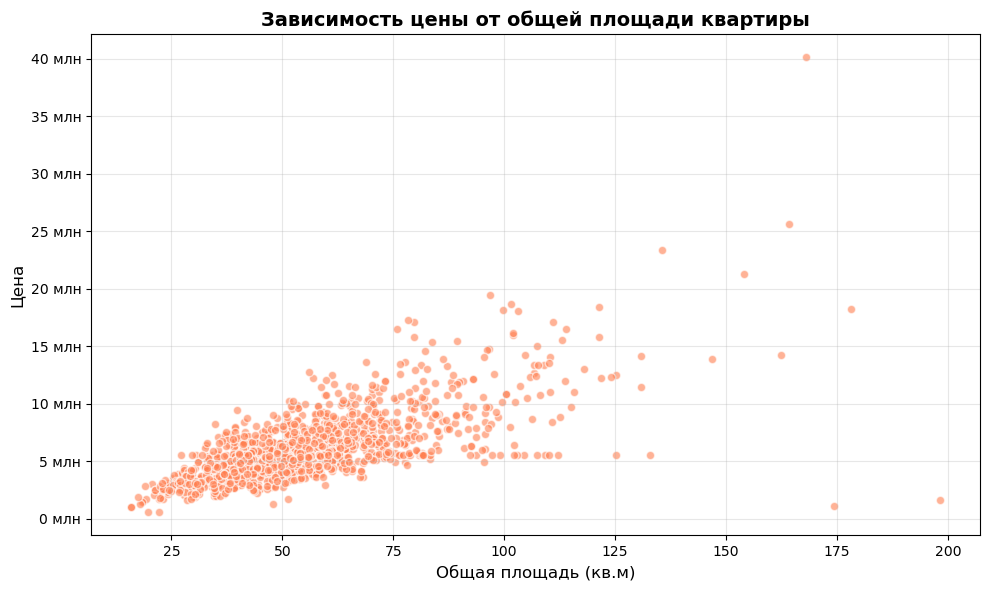

In [7]:
# строим заисимость цены от общей площади квартиры
plt.figure(figsize=(10, 6))

plt.scatter(dataset['area_total'], dataset['price'], alpha=0.6, color='coral', edgecolor='white')

plt.title('Зависимость цены от общей площади квартиры', fontsize=14, fontweight='bold')
plt.xlabel('Общая площадь (кв.м)', fontsize=12)
plt.ylabel('Цена', fontsize=12)
plt.grid(True, alpha=0.3)

def millions_formatter(x, pos):
    return f'{x/1_000_000:.0f} млн'

# Применяем функцию к оси Y
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(millions_formatter))
# ====================================

plt.tight_layout()
plt.show()

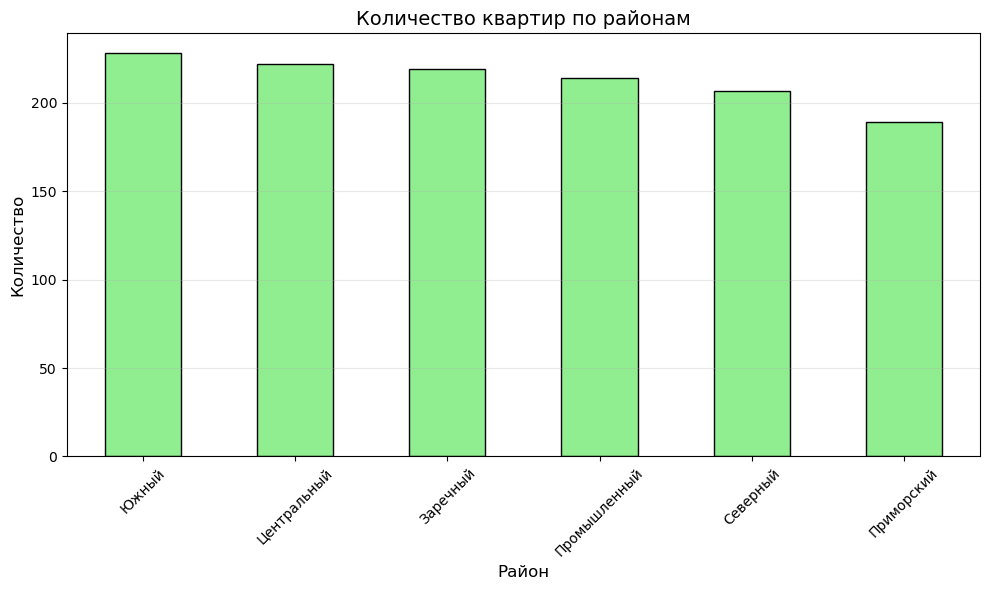

In [8]:
# Считаем количество квартир в каждом районе
district_counts = dataset['district'].value_counts()

# Строим столбчатую диаграмму
plt.figure(figsize=(10, 6))
district_counts.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Количество квартир по районам', fontsize=14)
plt.xlabel('Район', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.xticks(rotation=45)  # Поворот подписей, чтобы не наезжали
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()  # Чтобы ничего не обрезалось
plt.show()

In [9]:
#ИСПОЛЬЗОВАТЬ ТОЛЬКО ОДИН РАЗ, ПОТОМУ ЧТО ВСЁ ЛОМАЕТСЯ(снова всё заменяет) 
#в данном случае мы выбрали бинарный способ кодирования потому что либо есть балкон, либо его нет, 1 и 0 равнозначны
binary_mapping = {'да': 1, 'нет': 0}

dataset['has_balcony'] = dataset['has_balcony'].map(binary_mapping)
dataset['has_parking'] = dataset['has_parking'].map(binary_mapping)

print("Бинарные признаки закодированы:")
print(dataset[['has_balcony', 'has_parking']].head())


# Используем pd.get_dummies() - самый простой способ
dataset_encoded = pd.get_dummies(
    dataset, 
    columns=['district', 'building_type'],
    prefix=['district', 'building_type'],
    drop_first=False  # Оставляем все категории (для интерпретируемости)
)

print(f"\nРазмер датасета до кодирования: {dataset.shape}")
print(f"Размер датасета после кодирования: {dataset_encoded.shape}")

# Показываем новые столбцы
new_columns = [col for col in dataset_encoded.columns if col not in dataset.columns]
print(f"\nСоздано {len(new_columns)} новых столбцов:")
print(new_columns)

dataset[['has_balcony', 'has_parking']].head()

Бинарные признаки закодированы:
   has_balcony  has_parking
0            1            1
1            1            0
2            1            0
3            1            1
4            1            0

Размер датасета до кодирования: (1279, 18)
Размер датасета после кодирования: (1279, 26)

Создано 10 новых столбцов:
['district_Заречный', 'district_Приморский', 'district_Промышленный', 'district_Северный', 'district_Центральный', 'district_Южный', 'building_type_вторичка', 'building_type_новостройка', 'building_type_панельный', 'building_type_сталинка']


,has_balcony,has_parking
0,1,1
1,1,0
2,1,0
3,1,1
4,1,0


In [10]:
# кодируем и ранжируем степени ремонта
renovation_mapping = {
    'без ремонта': 0,
    'косметический': 1,
    'евроремонт': 2,
    'дизайнерский': 3

}

dataset_encoded['renovation_encoded'] = dataset['renovation'].map(renovation_mapping)
# Проверяем результат
print("\nРаспределение закодированного ремонта:")
print(dataset_encoded['renovation_encoded'].value_counts().sort_index())

correlation = dataset_encoded['renovation_encoded'].corr(dataset['price'])
print(f"\nКорреляция между качеством ремонта и ценой: {correlation:.4f}")


Распределение закодированного ремонта:
renovation_encoded
0    374
1    393
2    362
3    150
Name: count, dtype: int64

Корреляция между качеством ремонта и ценой: 0.2587


In [11]:
# новые признаки
# относительный этаж
dataset['floor_ratio'] = dataset['floor'] / dataset['floors_in_building']
dataset['floor_ratio'] = dataset['floor_ratio'].astype('float').round(2)

# floor_ratio = 0.2 - плохой выбор, слишком низко
# floor_ratio = 1.0 - плохой выбор, слишком высоко
# floor_ratio ≈ 0.3–0.7 - хороший выбор, не слишком высоко, не слишком низко
# Проверяем результат
print("\nСтатистика по относительному этажу:")
print(dataset['floor_ratio'].describe())
dataset[50:100]


Статистика по относительному этажу:
count    1279.000000
mean        0.545520
std         0.286893
min         0.040000
25%         0.300000
50%         0.550000
75%         0.800000
max         1.000000
Name: floor_ratio, dtype: float64


,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value,floor_ratio
50,SG-100050,Приморский,93.60,58.0,14.5,4,6,17,2.59,вторичка,2014,евроремонт,1,0,2.0,7.27,5547000.0,8549000.0,0.35
51,SG-100051,Заречный,47.70,29.3,8.8,2,1,17,2.73,новостройка,2019,дизайнерский,1,0,0.5,2.60,7588800.0,57556000.0,0.06
52,SG-100052,Центральный,110.33,68.7,16.4,4,6,16,2.58,панельный,1983,косметический,1,0,0.6,1.89,14037000.0,10987000.0,0.38
53,SG-100053,Заречный,58.80,36.1,9.2,2,5,13,2.53,панельный,1975,без ремонта,0,0,1.6,3.20,3897000.0,3246000.0,0.38
54,SG-100054,Заречный,63.30,34.1,8.2,3,4,12,2.79,вторичка,2009,без ремонта,1,0,6.8,13.50,4987000.0,3998000.0,0.33
55,SG-100055,Северный,46.40,30.4,4.0,2,11,14,2.79,вторичка,2006,евроремонт,1,0,0.1,6.28,5664000.0,4636000.0,0.79
56,SG-100056,Приморский,43.90,28.0,4.0,2,5,13,2.64,вторичка,2008,косметический,0,0,0.1,9.57,5531000.0,4689000.0,0.38
57,SG-100057,Приморский,47.20,32.3,5.7,2,3,5,2.62,панельный,1991,евроремонт,1,0,0.1,12.67,6050000.0,4630000.0,0.60
58,SG-100058,Заречный,77.70,52.7,4.2,3,1,5,2.59,панельный,1987,без ремонта,1,0,1.0,3.41,4913000.0,4037000.0,0.20
59,SG-100059,Центральный,48.50,33.0,7.2,2,4,5,2.51,панельный,1972,без ремонта,1,0,3.1,5.42,5547000.0,3586000.0,0.80


In [12]:
#Ещё один новый признак - Доля жилой площади
dataset['living_ratio'] = dataset['area_living'] / dataset['area_total']
dataset['living_ratio'] = dataset['living_ratio'].astype('float').round(2)
# если 0.65 - 0.8 - такие квартиры хорошие, много жилой площади
# если 0.4 - 0.5 - обычно либо средние, либо дешёвые, т.к. мало жилой площади

# Проверяем результат
print("\nСтатистика по доле жилой площади:")
print(dataset['living_ratio'].describe())
dataset[50:100]


Статистика по доле жилой площади:
count    1279.000000
mean        0.619335
std         0.060049
min         0.050000
25%         0.590000
50%         0.620000
75%         0.650000
max         0.940000
Name: living_ratio, dtype: float64


,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value,floor_ratio,living_ratio
50,SG-100050,Приморский,93.60,58.0,14.5,4,6,17,2.59,вторичка,2014,евроремонт,1,0,2.0,7.27,5547000.0,8549000.0,0.35,0.62
51,SG-100051,Заречный,47.70,29.3,8.8,2,1,17,2.73,новостройка,2019,дизайнерский,1,0,0.5,2.60,7588800.0,57556000.0,0.06,0.61
52,SG-100052,Центральный,110.33,68.7,16.4,4,6,16,2.58,панельный,1983,косметический,1,0,0.6,1.89,14037000.0,10987000.0,0.38,0.62
53,SG-100053,Заречный,58.80,36.1,9.2,2,5,13,2.53,панельный,1975,без ремонта,0,0,1.6,3.20,3897000.0,3246000.0,0.38,0.61
54,SG-100054,Заречный,63.30,34.1,8.2,3,4,12,2.79,вторичка,2009,без ремонта,1,0,6.8,13.50,4987000.0,3998000.0,0.33,0.54
55,SG-100055,Северный,46.40,30.4,4.0,2,11,14,2.79,вторичка,2006,евроремонт,1,0,0.1,6.28,5664000.0,4636000.0,0.79,0.66
56,SG-100056,Приморский,43.90,28.0,4.0,2,5,13,2.64,вторичка,2008,косметический,0,0,0.1,9.57,5531000.0,4689000.0,0.38,0.64
57,SG-100057,Приморский,47.20,32.3,5.7,2,3,5,2.62,панельный,1991,евроремонт,1,0,0.1,12.67,6050000.0,4630000.0,0.60,0.68
58,SG-100058,Заречный,77.70,52.7,4.2,3,1,5,2.59,панельный,1987,без ремонта,1,0,1.0,3.41,4913000.0,4037000.0,0.20,0.68
59,SG-100059,Центральный,48.50,33.0,7.2,2,4,5,2.51,панельный,1972,без ремонта,1,0,3.1,5.42,5547000.0,3586000.0,0.80,0.68


In [13]:
#делаем копию чтоб масштабировать и выводить гипотезы:
dataset_copy = dataset.copy()
dataset_copy

,id,district,area_total,area_living,area_kitchen,rooms,floor,floors_in_building,ceiling_height,building_type,year_built,renovation,has_balcony,has_parking,metro_distance_km,center_distance_km,price,cadastral_value,floor_ratio,living_ratio
0,SG-100000,Центральный,42.80,25.8,4.0,2,5,15,2.51,панельный,1990,косметический,1,1,1.5,4.20,5291000.0,4125000.0,0.33,0.60
1,SG-100001,Промышленный,45.53,27.4,5.0,2,3,11,2.56,панельный,1986,евроремонт,1,0,0.8,3.44,3634000.0,2925000.0,0.27,0.60
2,SG-100002,Центральный,29.00,17.5,4.0,1,9,9,2.65,панельный,1990,косметический,1,0,3.9,11.69,3291000.0,2729000.0,1.00,0.60
3,SG-100003,Северный,71.70,43.6,6.3,3,7,7,2.61,панельный,1964,без ремонта,1,1,1.0,1.81,6273000.0,4814000.0,1.00,0.61
4,SG-100004,Приморский,58.00,34.6,5.1,2,15,15,2.90,новостройка,2020,евроремонт,1,0,2.3,3.64,9832000.0,8324000.0,1.00,0.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1279,SG-101279,Промышленный,93.65,53.2,11.2,3,6,24,2.85,новостройка,2017,евроремонт,1,0,0.2,3.75,7901000.0,5647000.0,0.25,0.57
1280,SG-101280,Южный,56.70,32.9,11.3,2,6,14,2.74,вторичка,2013,евроремонт,1,0,1.6,2.26,7679000.0,6814000.0,0.43,0.58
1281,SG-101281,Приморский,33.00,19.7,4.5,1,6,8,3.03,сталинка,1960,косметический,1,0,0.1,2.49,4389000.0,3760000.0,0.75,0.60
1282,SG-101282,Приморский,47.10,26.8,7.8,2,7,13,3.00,новостройка,2019,без ремонта,1,0,0.1,4.31,5465000.0,4511000.0,0.54,0.57


In [14]:
# Масштабируем, не масштабируем только id, price(т.к. целевая)
# 'id' тоже удаляем, так как это просто идентификатор, а не признак.
target = 'price'
X = dataset_copy.drop(columns=[target, 'id', 'district', 'building_type', 'year_built', 'renovation'])
y = dataset_copy[target]

# Находим все числовые колонки в признаках (X)
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Числовые признаки для масштабирования:", numeric_cols)

# Инициализируем масштабировщик
# Для масштабирования числовых признаков был выбран метод MinMaxScaler, приводящий данные к диапазону [0, 1]. Данный выбор обоснован тем, что:
# На этапе предварительной очистки из датасета были удалены экстремальные выбросы, поэтому чувствительность MinMaxScaler к выбросам не является проблемой.
# Все признаки после масштабирования имеют одинаковый диапазон, что предотвращает доминирование признаков с большим исходным масштабом (например, цена в миллионах) над признаками с малым масштабом (например, количество комнат).
scaler = MinMaxScaler()

# Применяем масштабирование только к X
X_scaled_array = scaler.fit_transform(X[numeric_cols])

# Возвращаем данные обратно в формат DataFrame для удобства работы
X_scaled = pd.DataFrame(X_scaled_array, columns=numeric_cols, index=X.index)

#Добавляем обратно нечисловые признаки, если они есть
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
if categorical_cols:
    X_final = pd.concat([X_scaled, X[categorical_cols]], axis=1)
else:
    X_final = X_scaled

print("\nданные после масштабирования:")
print(X_final.head())

# X_final -> масштабированные признаки для подачи в модель
# y -> исходная целевая переменная (цена)

Числовые признаки для масштабирования: ['area_total', 'area_living', 'area_kitchen', 'rooms', 'floor', 'floors_in_building', 'ceiling_height', 'has_balcony', 'has_parking', 'metro_distance_km', 'center_distance_km', 'cadastral_value', 'floor_ratio', 'living_ratio']

данные после масштабирования:
   area_total  area_living  area_kitchen  rooms     floor  floors_in_building  \
0    0.147172     0.149621      0.000000    0.4  0.166667            0.545455   
1    0.162164     0.164773      0.045662    0.4  0.083333            0.363636   
2    0.071389     0.071023      0.000000    0.2  0.333333            0.272727   
3    0.305876     0.318182      0.105023    0.6  0.250000            0.181818   
4    0.230643     0.232955      0.050228    0.4  0.583333            0.545455   

   ceiling_height  has_balcony  has_parking  metro_distance_km  \
0        0.276471          1.0          1.0           0.078212   
1        0.286275          1.0          0.0           0.039106   
2        0.303922 

Гипотеза Н1: "чем лучше ремонт, тем выше цена квартиры"
Гипотеза Н0: "есть другой более значительный фактор, влияющий на цену, такой как район или этажность"

In [15]:
# 1. Группируем цены по типу ремонта (0, 1, 2, 3)
groups = [group['price'].values for name, group in dataset_encoded.groupby('renovation_encoded')]

# 2. Применяем тест Крускала-Уоллиса
# Он сравнивает медианы нескольких независимых групп
statistic, p_value = stats.kruskal(*groups)

# 3. Выводим результаты
alpha = 0.05  # Уровень значимости (стандартные 5%)

print("="*50)
print("ПРОВЕРКА ГИПОТЕЗЫ: Влияние типа ремонта на цену")
print("="*50)
print(f"Статистика теста (H): {statistic:.4f}")
print(f"P-value: {p_value:.4e}")  # Научный формат для очень маленьких чисел
print("-" * 50)

# 4. Интерпретация
if p_value < alpha:
    print(f"✅ ВЫВОД: p-value ({p_value:.4e}) < {alpha}")
    print("\nМы ОТВЕРГАЕМ нулевую гипотезу (H0).")
    print("\nСуществует статистически значимая разница в ценах между квартирами с разным типом ремонта.")
else:
    print(f"❌ ВЫВОД: p-value ({p_value:.4e}) >= {alpha}")
    print("\nМы НЕ МОЖЕМ отвергнуть нулевую гипотезу (H0).")
    print("\nСтатистически значимого влияния типа ремонта на цену не обнаружено.")

ПРОВЕРКА ГИПОТЕЗЫ: Влияние типа ремонта на цену
Статистика теста (H): 101.7730
P-value: 6.4601e-22
--------------------------------------------------
✅ ВЫВОД: p-value (6.4601e-22) < 0.05

Мы ОТВЕРГАЕМ нулевую гипотезу (H0).

Существует статистически значимая разница в ценах между квартирами с разным типом ремонта.


Проверка, что финальный датасет не содержит пропусков и дубликатов

In [16]:
print("=" * 60)
print("ПРОВЕРКА ПРОПУСКОВ")
print("=" * 60)

missing_values = dataset.isnull().sum()
total_missing = missing_values.sum()

print(f"Всего пропусков в датасете: {total_missing}")
print("\nПропуски по столбцам:")
print(missing_values[missing_values > 0])

if total_missing == 0:
    print("\n✅ Пропусков не обнаружено!")
else:
    print(f"\n⚠️ Найдено {total_missing} пропусков. Необходимо заполнить или удалить.")

# ============================================
# ПРОВЕРКА ДУБЛИКАТОВ
# ============================================
print("\n" + "=" * 60)
print("ПРОВЕРКА ДУБЛИКАТОВ")
print("=" * 60)

# Полные дубликаты (все столбцы одинаковы)
full_duplicates = dataset.duplicated().sum()
print(f"Полных дубликатов (все столбцы): {full_duplicates}")

# Дубликаты по ID
id_duplicates = dataset['id'].duplicated().sum()
print(f"Дубликатов по ID: {id_duplicates}")

if full_duplicates == 0 and id_duplicates == 0:
    print("\n✅ Дубликатов не обнаружено!")
else:
    print(f"\n️ Найдено {full_duplicates + id_duplicates} дубликатов.")

# ============================================
# ИТОГОВАЯ ИНФОРМАЦИЯ
# ============================================
print("\n" + "=" * 60)
print("ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 60)
print(f"Количество строк: {dataset.shape[0]}")
print(f"Количество столбцов: {dataset.shape[1]}")

ПРОВЕРКА ПРОПУСКОВ
Всего пропусков в датасете: 0

Пропуски по столбцам:
Series([], dtype: int64)

✅ Пропусков не обнаружено!

ПРОВЕРКА ДУБЛИКАТОВ
Полных дубликатов (все столбцы): 0
Дубликатов по ID: 0

✅ Дубликатов не обнаружено!

ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ
Количество строк: 1279
Количество столбцов: 20


In [17]:
print("=" * 60)
print("ПРОВЕРКА ПРОПУСКОВ")
print("=" * 60)

missing_values = dataset_encoded.isnull().sum()
total_missing = missing_values.sum()

print(f"Всего пропусков в датасете: {total_missing}")
print("\nПропуски по столбцам:")
print(missing_values[missing_values > 0])

if total_missing == 0:
    print("\n✅ Пропусков не обнаружено!")
else:
    print(f"\n⚠️ Найдено {total_missing} пропусков. Необходимо заполнить или удалить.")

# ============================================
# ПРОВЕРКА ДУБЛИКАТОВ
# ============================================
print("\n" + "=" * 60)
print("ПРОВЕРКА ДУБЛИКАТОВ")
print("=" * 60)

# Полные дубликаты (все столбцы одинаковы)
full_duplicates = dataset_encoded.duplicated().sum()
print(f"Полных дубликатов (все столбцы): {full_duplicates}")

# Дубликаты по ID
id_duplicates = dataset_encoded['id'].duplicated().sum()
print(f"Дубликатов по ID: {id_duplicates}")

if full_duplicates == 0 and id_duplicates == 0:
    print("\n✅ Дубликатов не обнаружено!")
else:
    print(f"\n️ Найдено {full_duplicates + id_duplicates} дубликатов.")

# ============================================
# ИТОГОВАЯ ИНФОРМАЦИЯ
# ============================================
print("\n" + "=" * 60)
print("ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 60)
print(f"Количество строк: {dataset_encoded.shape[0]}")
print(f"Количество столбцов: {dataset_encoded.shape[1]}")

ПРОВЕРКА ПРОПУСКОВ
Всего пропусков в датасете: 0

Пропуски по столбцам:
Series([], dtype: int64)

✅ Пропусков не обнаружено!

ПРОВЕРКА ДУБЛИКАТОВ
Полных дубликатов (все столбцы): 0
Дубликатов по ID: 0

✅ Дубликатов не обнаружено!

ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ
Количество строк: 1279
Количество столбцов: 27


In [18]:
print("=" * 60)
print("ПРОВЕРКА ПРОПУСКОВ")
print("=" * 60)

missing_values = dataset_copy.isnull().sum()
total_missing = missing_values.sum()

print(f"Всего пропусков в датасете: {total_missing}")
print("\nПропуски по столбцам:")
print(missing_values[missing_values > 0])

if total_missing == 0:
    print("\n✅ Пропусков не обнаружено!")
else:
    print(f"\n⚠️ Найдено {total_missing} пропусков. Необходимо заполнить или удалить.")

# ============================================
# ПРОВЕРКА ДУБЛИКАТОВ
# ============================================
print("\n" + "=" * 60)
print("ПРОВЕРКА ДУБЛИКАТОВ")
print("=" * 60)

# Полные дубликаты (все столбцы одинаковы)
full_duplicates = dataset_copy.duplicated().sum()
print(f"Полных дубликатов (все столбцы): {full_duplicates}")

# Дубликаты по ID
id_duplicates = dataset_encoded['id'].duplicated().sum()
print(f"Дубликатов по ID: {id_duplicates}")

if full_duplicates == 0 and id_duplicates == 0:
    print("\n✅ Дубликатов не обнаружено!")
else:
    print(f"\n️ Найдено {full_duplicates + id_duplicates} дубликатов.")

# ============================================
# ИТОГОВАЯ ИНФОРМАЦИЯ
# ============================================
print("\n" + "=" * 60)
print("ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 60)
print(f"Количество строк: {dataset_encoded.shape[0]}")
print(f"Количество столбцов: {dataset_encoded.shape[1]}")

ПРОВЕРКА ПРОПУСКОВ
Всего пропусков в датасете: 0

Пропуски по столбцам:
Series([], dtype: int64)

✅ Пропусков не обнаружено!

ПРОВЕРКА ДУБЛИКАТОВ
Полных дубликатов (все столбцы): 0
Дубликатов по ID: 0

✅ Дубликатов не обнаружено!

ИТОГОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ
Количество строк: 1279
Количество столбцов: 27


Почему я сделал 3 датафрейма? чтобы удобнее с ними работать, работать одновременно с 27 столбцами с ненужными признаками(новыми) для гипотезы - это лишнее, т.к. можно запутаться. Как я использовал их:
1. Для введения новых признаков и чистки от аномалий/пропусков/дубликатов использовалась основа для других df - dataset
2. Для масштабирования использовался dataset_copy, чтобы оценить наличие аномалий
3. Для проверки гипотезы использовался dataset_encoded

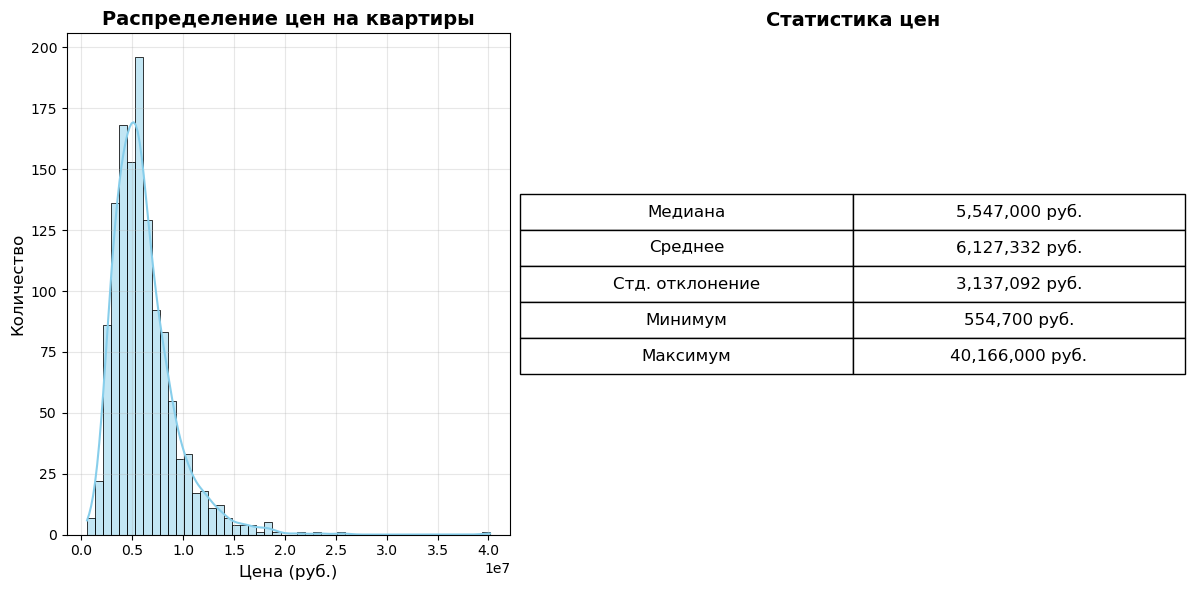

In [22]:
plt.figure(figsize=(12, 6))

# Гистограмма цен
plt.subplot(1, 2, 1)
sns.histplot(dataset['price'], bins=50, kde=True, color='skyblue')
plt.title('Распределение цен на квартиры', fontsize=14, fontweight='bold')
plt.xlabel('Цена (руб.)', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.grid(True, alpha=0.3)

# Статистика
median_price = dataset['price'].median()
mean_price = dataset['price'].mean()
std_price = dataset['price'].std()

plt.subplot(1, 2, 2)
stats_data = [
    ['Медиана', f'{median_price:,.0f} руб.'],
    ['Среднее', f'{mean_price:,.0f} руб.'],
    ['Стд. отклонение', f'{std_price:,.0f} руб.'],
    ['Минимум', f'{dataset["price"].min():,.0f} руб.'],
    ['Максимум', f'{dataset["price"].max():,.0f} руб.']
]
plt.axis('off')
table = plt.table(cellText=stats_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.5, 2)
plt.title('Статистика цен', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

#print(f"\n ВЫВОД 1:")
#print(f"Медианная цена квартиры составляет {median_price:,.0f} рублей.")
#print(f"Средняя цена ({mean_price:,.0f} руб.) выше медианы, что указывает на наличие дорогих квартир,")
#print(f"которые 'тянут' среднее вверх. Разброс цен очень большой: от {dataset['price'].min():,.0f} до {dataset['price'].max():,.0f} рублей.")

ВЫВОД 1:
Медианная цена квартиры составляет 5,547,000 рублей.
Средняя цена (6,127,332 руб.) выше медианы, что указывает на наличие дорогих квартир,
которые 'тянут' среднее вверх. Разброс цен очень большой: от 554,700 до 40,166,000 рублей.

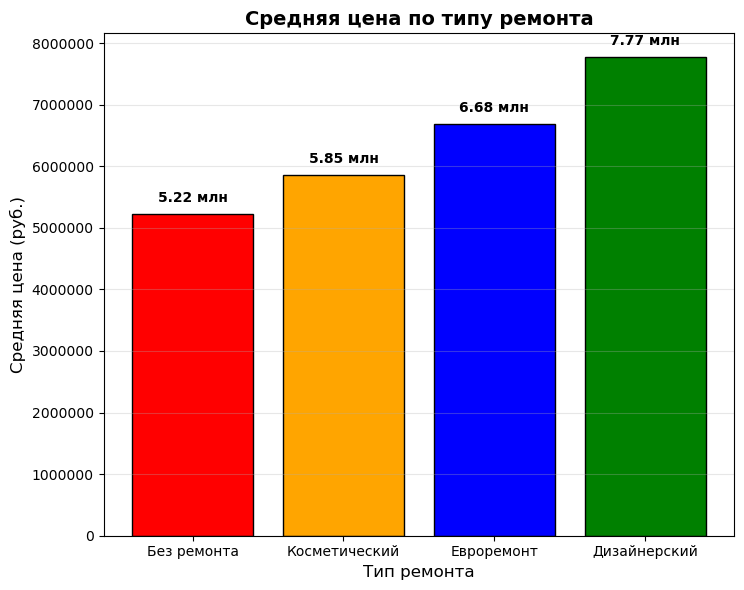

In [35]:
plt.figure(figsize=(14, 6))

# Средняя цена по типам ремонта
plt.subplot(1, 2, 2)
avg_price_by_renovation = dataset_encoded.groupby('renovation_encoded')['price'].mean()
colors = ['red', 'orange', 'blue', 'green']
bars = plt.bar(avg_price_by_renovation.index, avg_price_by_renovation.values, color=colors, edgecolor='black')
plt.title('Средняя цена по типу ремонта', fontsize=14, fontweight='bold')
plt.xlabel('Тип ремонта', fontsize=12)
plt.ylabel('Средняя цена (руб.)', fontsize=12)
plt.xticks([0, 1, 2, 3], ['Без ремонта', 'Косметический', 'Евроремонт', 'Дизайнерский'])
plt.grid(True, alpha=0.3, axis='y')
plt.ticklabel_format(style='plain', axis='y')

# Добавляем значения на столбцы
for bar, value in zip(bars, avg_price_by_renovation.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200000, 
             f'{value/1000000:.2f} млн', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Статистика
#print(f"\nВЫВОД 2:")
#print(f"Квартиры с дизайнерским ремонтом стоят в среднем {avg_price_by_renovation[3]/1000000:.2f} млн рублей,")
#print(f"что на {((avg_price_by_renovation[3] / avg_price_by_renovation[0]) - 1) * 100:.1f}% дороже квартир без ремонта")
#print(f"({avg_price_by_renovation[0]/1000000:.2f} млн рублей).")
#print(f"Качество ремонта положительно коррелирует с ценой (коэффициент корреляции: {dataset_encoded['renovation_encoded'].corr(dataset_encoded['price']):.3f}).")

ВЫВОД 2:
Квартиры с дизайнерским ремонтом стоят в среднем 7.77 млн рублей,
что на 48.9% дороже квартир без ремонта
(5.22 млн рублей).
Качество ремонта положительно коррелирует с ценой (коэффициент корреляции: 0.259).

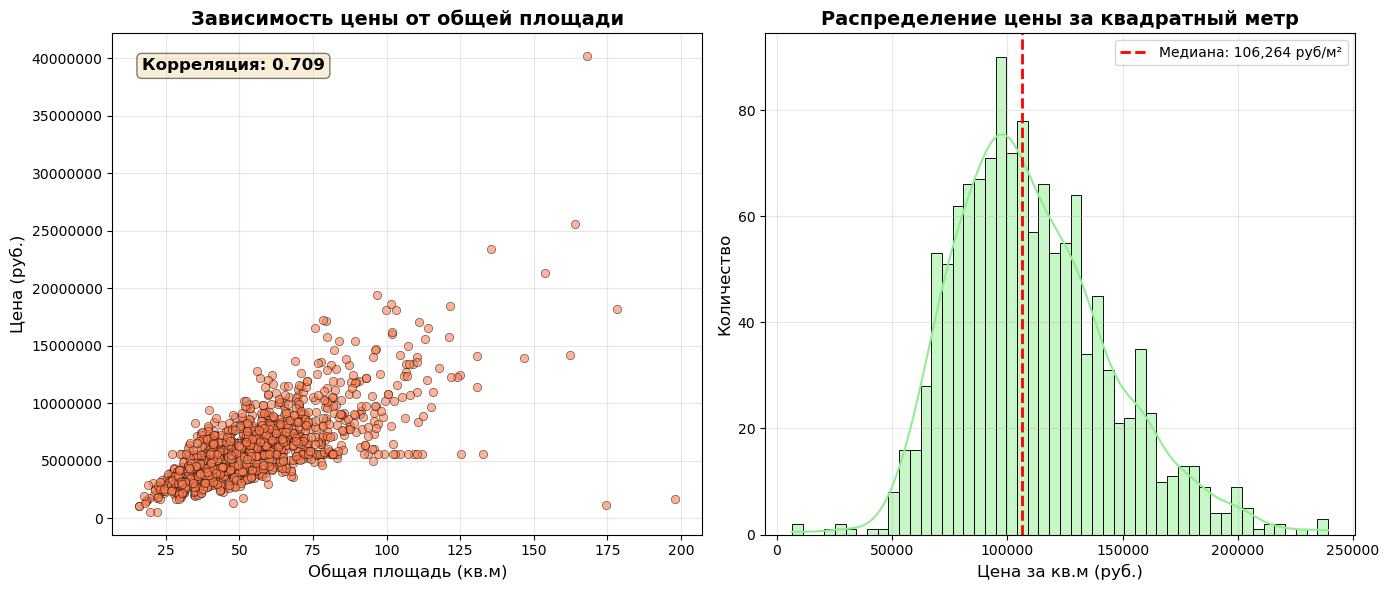

In [40]:
plt.figure(figsize=(14, 6))

# Scatter plot
plt.subplot(1, 2, 1)
plt.scatter(dataset['area_total'], dataset['price'], alpha=0.6, color='coral', edgecolors='black', linewidth=0.5)
plt.title('Зависимость цены от общей площади', fontsize=14, fontweight='bold')
plt.xlabel('Общая площадь (кв.м)', fontsize=12)
plt.ylabel('Цена (руб.)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='y')

# Корреляция
correlation = dataset['area_total'].corr(dataset['price'])
plt.text(0.05, 0.95, f'Корреляция: {correlation:.3f}', 
         transform=plt.gca().transAxes, fontsize=12, fontweight='bold',
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Цена за квадратный метр
dataset['price_per_m2'] = dataset['price'] / dataset['area_total']

plt.subplot(1, 2, 2)
sns.histplot(dataset['price_per_m2'], bins=50, kde=True, color='lightgreen')
plt.title('Распределение цены за квадратный метр', fontsize=14, fontweight='bold')
plt.xlabel('Цена за кв.м (руб.)', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.grid(True, alpha=0.3)

median_price_per_m2 = dataset['price_per_m2'].median()
plt.axvline(median_price_per_m2, color='red', linestyle='--', linewidth=2, label=f'Медиана: {median_price_per_m2:,.0f} руб/м²')
plt.legend()

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

#print(f"\n📊 ВЫВОД 3:")
#print(f"Корреляция между площадью и ценой составляет {correlation:.3f}, что указывает на умеренную положительную связь.")
#print(f"Медианная цена за квадратный метр: {median_price_per_m2:,.0f} рублей.")

ВЫВОД 3:
Корреляция между площадью и ценой составляет 0.709, что указывает на умеренную положительную связь.
Медианная цена за квадратный метр: 106,264 рублей.

Спасибо за прочтение, до свидания!

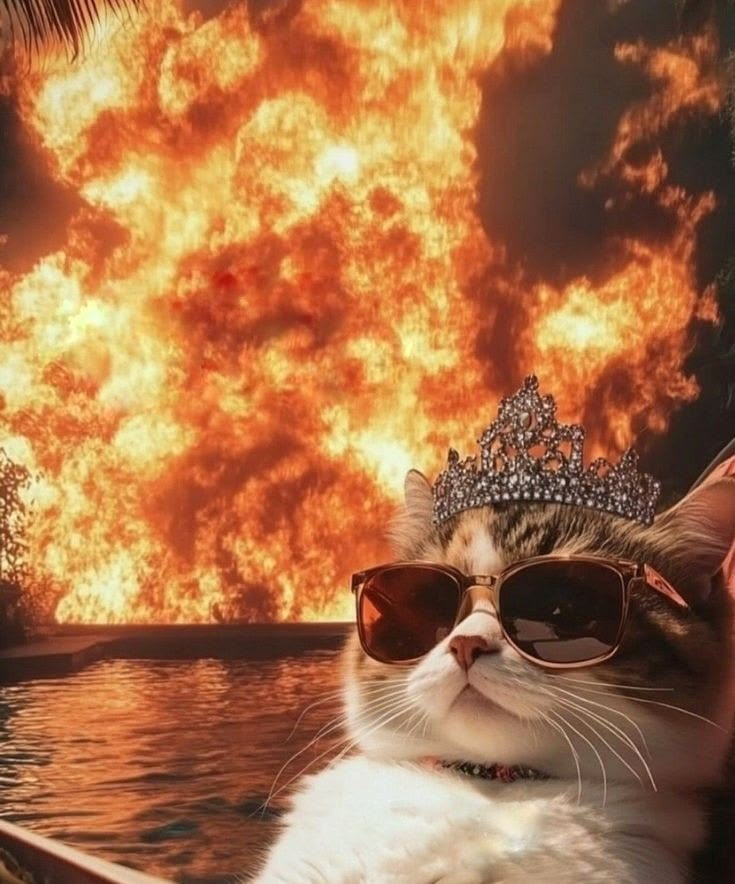

In [62]:
img = Image.open("PAKA.jpg")

img